In [1]:
# =====================================================================
# CELL 1: Environment Setup & Forecast Data Ingestion
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

print("=" * 65)
print("PHASE 4: INVENTORY SIMULATION & SUPPLY CHAIN OPTIMIZATION")
print("=" * 65)

# 1. Load Forecasts and Metadata
forecast_file = "tft_test_forecasts.csv"
pairs_file = "selected_pairs.csv"

assert os.path.exists(forecast_file), f"Missing {forecast_file}! Please check directory."
assert os.path.exists(pairs_file), f"Missing {pairs_file}! Please check directory."

df_forecasts = pd.read_csv(forecast_file)
df_pairs = pd.read_csv(pairs_file)

print(f"Loaded {len(df_forecasts):,} test forecast windows from '{forecast_file}'.")
print(f"Loaded metadata for {len(df_pairs):,} store-item pairs from '{pairs_file}'.")

# 2. Inspect Structure and Unique Counts
unique_pairs_fc = df_forecasts[["store_nbr", "item_nbr"]].drop_duplicates()
unique_stores = df_forecasts["store_nbr"].nunique()
unique_items = df_forecasts["item_nbr"].nunique()
start_dates = df_forecasts["target_start_date"].unique()

print(f"\nData Verification:")
print(f"  - Unique Store-Item Pairs in Forecasts: {len(unique_pairs_fc):4d} / 400")
print(f"  - Unique Stores Represented           : {unique_stores:4d}")
print(f"  - Unique Items Represented            : {unique_items:4d}")
print(f"  - Target Rolling Windows Start Dates  : {len(start_dates):4d} ({start_dates[0]} to {start_dates[-1]})")

# 3. Overall Actual vs Predicted Demand on Test Set
actual_cols = [f"actual_day_{d+1}" for d in range(7)]
pred_cols   = [f"pred_day_{d+1}" for d in range(7)]

total_actual = df_forecasts[actual_cols].values.sum()
total_pred   = df_forecasts[pred_cols].values.sum()
bias_percent = ((total_pred - total_actual) / total_actual) * 100

print(f"\nTest Horizon Demand Summary (All 7 Days Combined):")
print(f"  - Total Actual Demand   : {total_actual:12,.1f} units")
print(f"  - Total Predicted Demand: {total_pred:12,.1f} units")
print(f"  - Net Forecast Bias     : {bias_percent:+.2f}%")

# 4. Merge Product Metadata (Perishability & Family)
meta_cols = ["store_nbr", "item_nbr", "family", "class", "perishable", "average_sales"]
df_merged = df_forecasts.merge(df_pairs[meta_cols], on=["store_nbr", "item_nbr"], how="left")

perishable_count = df_pairs["perishable"].sum()
non_perishable_count = len(df_pairs) - perishable_count

print(f"\nProduct Portfolio Composition:")
print(f"  - Non-Perishable Items : {non_perishable_count} pairs ({non_perishable_count/400*100:.1f}%)")
print(f"  - Perishable Items     : {perishable_count} pairs ({perishable_count/400*100:.1f}%)")
print("=" * 65)
print("STATUS: Forecast and metadata verified successfully!")
print("=" * 65)

PHASE 4: INVENTORY SIMULATION & SUPPLY CHAIN OPTIMIZATION
Loaded 3,237 test forecast windows from 'tft_test_forecasts.csv'.
Loaded metadata for 400 store-item pairs from 'selected_pairs.csv'.

Data Verification:
  - Unique Store-Item Pairs in Forecasts:  363 / 400
  - Unique Stores Represented           :   53
  - Unique Items Represented            :  113
  - Target Rolling Windows Start Dates  :    9 (2017-08-01 to 2017-08-09)

Test Horizon Demand Summary (All 7 Days Combined):
  - Total Actual Demand   :  1,002,968.2 units
  - Total Predicted Demand:    991,399.1 units
  - Net Forecast Bias     : -1.15%

Product Portfolio Composition:
  - Non-Perishable Items : 196 pairs (49.0%)
  - Perishable Items     : 204 pairs (51.0%)
STATUS: Forecast and metadata verified successfully!


COMPUTING DYNAMIC SAFETY STOCKS & FORECAST ERROR VARIANCE
Safety Stock Analysis at 95% Service Level (z = 1.645):
  - Classical Heuristic Total Safety Stock : 32,142.000000 units (Mean:  88.5 units/pair)
  - TFT Predictive Total Safety Stock      : 22,431.000000 units (Mean:  61.8 units/pair)
  - Inventory Buffer Capital Reduction     :  30.21% LESS inventory needed!

SAFETY STOCK BY PERISHABILITY (95% SERVICE LEVEL):
                               Classical SS (units)  TFT SS (units)  Buffer Reduction (%)
Non-Perishable (Shelf-Stable)                 93.91           77.19                 32.89
Perishable (Fresh / Chilled)                  82.78           45.25                 34.33


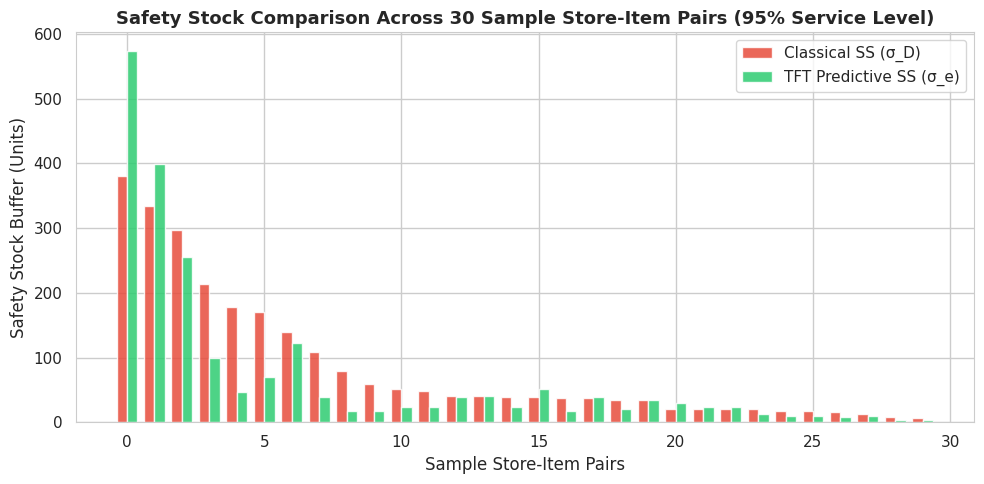

Saved safety stock visualization as 'safety_stock_comparison.png'!


In [2]:
# =====================================================================
# CELL 2: Dynamic Safety Stock (SS) Formulation & Buffer Reduction
# =====================================================================
from scipy.stats import norm

print("=" * 65)
print("COMPUTING DYNAMIC SAFETY STOCKS & FORECAST ERROR VARIANCE")
print("=" * 65)

# 1. Calculate Cumulative 7-Day Lead-Time Demand and Forecast per Window
lead_time_days = 7
df_forecasts["actual_lead_time_demand"] = df_forecasts[actual_cols].sum(axis=1)
df_forecasts["pred_lead_time_demand"]   = df_forecasts[pred_cols].sum(axis=1)

# Error on cumulative lead-time demand: e_L = actual - predicted
df_forecasts["lead_time_error"] = (
    df_forecasts["actual_lead_time_demand"] - df_forecasts["pred_lead_time_demand"]
)

# 2. Per-Pair Error Statistics and Raw Demand Statistics
pair_stats = []
for (store_nbr, item_nbr), group in df_forecasts.groupby(["store_nbr", "item_nbr"]):
    # Lead-time forecast error std dev (sigma_e_L)
    sigma_e_L = group["lead_time_error"].std(ddof=1)
    if pd.isna(sigma_e_L) or sigma_e_L < 1e-3:
        sigma_e_L = np.std(group["lead_time_error"]) + 1.0  # fallback for single-window edge cases

    # Daily raw demand std dev (sigma_D) across all 7 days in window
    raw_daily_demand = group[actual_cols].values.flatten()
    sigma_D = np.std(raw_daily_demand, ddof=1)
    mean_D  = np.mean(raw_daily_demand)

    # Lead-time demand std dev under Classical random-walk: sqrt(L) * sigma_D
    sigma_classical_L = np.sqrt(lead_time_days) * sigma_D

    pair_stats.append({
        "store_nbr": store_nbr,
        "item_nbr": item_nbr,
        "mean_daily_demand": mean_D,
        "sigma_D": sigma_D,
        "sigma_classical_L": sigma_classical_L,
        "sigma_e_L": sigma_e_L,
        "variance_reduction_%": max(0.0, (1 - (sigma_e_L / (sigma_classical_L + 1e-6))) * 100)
    })

df_ss = pd.DataFrame(pair_stats)
df_ss = df_ss.merge(df_pairs[["store_nbr", "item_nbr", "family", "class", "perishable"]], on=["store_nbr", "item_nbr"], how="left")

# 3. Calculate Safety Stock at 90%, 95%, and 98% Service Levels
service_levels = [0.90, 0.95, 0.98]
for sl in service_levels:
    z = norm.ppf(sl)
    df_ss[f"SS_TFT_{int(sl*100)}%"]       = np.ceil(z * df_ss["sigma_e_L"])
    df_ss[f"SS_Classical_{int(sl*100)}%"] = np.ceil(z * df_ss["sigma_classical_L"])

# 4. Summary Findings: Working Capital & Buffer Reduction at 95% Service Level
mean_ss_tft       = df_ss["SS_TFT_95%"].mean()
mean_ss_classical = df_ss["SS_Classical_95%"].mean()
total_ss_tft       = df_ss["SS_TFT_95%"].sum()
total_ss_classical = df_ss["SS_Classical_95%"].sum()
reduction_pct     = ((total_ss_classical - total_ss_tft) / total_ss_classical) * 100

print(f"Safety Stock Analysis at 95% Service Level (z = {norm.ppf(0.95):.3f}):")
print(f"  - Classical Heuristic Total Safety Stock : {total_ss_classical:10,f} units (Mean: {mean_ss_classical:5.1f} units/pair)")
print(f"  - TFT Predictive Total Safety Stock      : {total_ss_tft:10,f} units (Mean: {mean_ss_tft:5.1f} units/pair)")
print(f"  - Inventory Buffer Capital Reduction     : {reduction_pct:6.2f}% LESS inventory needed!")

# 5. Category Breakdown: Perishable vs Non-Perishable
print("\n" + "=" * 65)
print("SAFETY STOCK BY PERISHABILITY (95% SERVICE LEVEL):")
print("=" * 65)
perish_summary = df_ss.groupby("perishable")[["SS_Classical_95%", "SS_TFT_95%", "variance_reduction_%"]].mean()
perish_summary.index = ["Non-Perishable (Shelf-Stable)", "Perishable (Fresh / Chilled)"]
perish_summary.columns = ["Classical SS (units)", "TFT SS (units)", "Buffer Reduction (%)"]
print(perish_summary.round(2).to_string())
print("=" * 65)

# 6. Plot Safety Stock Reduction Comparison
fig, ax = plt.subplots(figsize=(10, 5))
sample_pairs = df_ss.sample(n=30, random_state=42).sort_values("SS_Classical_95%", ascending=False)
x = np.arange(len(sample_pairs))
width = 0.38

ax.bar(x - width/2, sample_pairs["SS_Classical_95%"], width, label="Classical SS (σ_D)", color="#e74c3c", alpha=0.85)
ax.bar(x + width/2, sample_pairs["SS_TFT_95%"], width, label="TFT Predictive SS (σ_e)", color="#2ecc71", alpha=0.85)
ax.set_title("Safety Stock Comparison Across 30 Sample Store-Item Pairs (95% Service Level)", fontsize=13, fontweight="bold")
ax.set_ylabel("Safety Stock Buffer (Units)")
ax.set_xlabel("Sample Store-Item Pairs")
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("safety_stock_comparison.png", dpi=300)
plt.show()
print("Saved safety stock visualization as 'safety_stock_comparison.png'!")

In [3]:
# =====================================================================
# CELL 3: Daily Discrete-Event Inventory Replenishment Simulator
# =====================================================================
import pandas as pd
import numpy as np

print("=" * 65)
print("BUILDING DAILY DISCRETE-EVENT INVENTORY SIMULATOR")
print("=" * 65)

# 1. Economic Cost Parameters
UNIT_HOLDING_COST_DRY    = 0.10   # $ / unit / day for shelf-stable
UNIT_HOLDING_COST_PERISH = 0.15   # $ / unit / day for chilled / perishable
STOCKOUT_PENALTY_PER_UNIT = 2.50  # $ / unit of unmet demand
FIXED_ORDER_COST          = 8.00  # $ / purchase order placed
LEAD_TIME_DAYS            = 7     # Logistics lead time (days)

# 2. Extract 15-Day Continuous Demand and Forecast Series per Pair
# We pivot rolling 7-day windows to get continuous actual & predicted daily demand (Aug 1 to Aug 15)
test_dates = [f"2017-08-{d:02d}" for d in range(1, 16)]

# Build continuous daily matrix for all 363 active pairs
pair_daily_actual = {}
pair_daily_pred = {}
pair_is_perishable = {}

for (s_nbr, i_nbr), group in df_forecasts.groupby(["store_nbr", "item_nbr"]):
    group = group.sort_values("target_start_date")
    # Take the 1-step ahead predictions as daily operational forecasts
    daily_act = []
    daily_fc = []
    for _, row in group.iterrows():
        daily_act.append(row["actual_day_1"])
        daily_fc.append(row["pred_day_1"])
    
    # Pad to 15 days if series is shorter
    if len(daily_act) < 15:
        # Append remaining days from the last window's multi-step vector
        last_row = group.iloc[-1]
        needed = 15 - len(daily_act)
        for step in range(2, 2 + needed):
            daily_act.append(last_row[f"actual_day_{min(step, 7)}"])
            daily_fc.append(last_row[f"pred_day_{min(step, 7)}"])

    pair_daily_actual[(s_nbr, i_nbr)] = np.array(daily_act[:15], dtype=np.float64)
    pair_daily_pred[(s_nbr, i_nbr)]   = np.array(daily_fc[:15], dtype=np.float64)
    
    # Perishability flag
    is_p = df_pairs[(df_pairs["store_nbr"] == s_nbr) & (df_pairs["item_nbr"] == i_nbr)]["perishable"].values
    pair_is_perishable[(s_nbr, i_nbr)] = bool(is_p[0]) if len(is_p) > 0 else False

print(f"Constructed 15-day continuous operational simulation series for {len(pair_daily_actual)} store-item pairs.")

# 3. Modular Discrete-Event Simulation Function
def run_inventory_simulation(reorder_factor_z=1.645, target_days_cover=4.0, use_tft=True):
    """
    Simulates daily replenishment across all store-item pairs over 15 days.
    - reorder_factor_z: Safety stock multiplier (z-score for reorder point s)
    - target_days_cover: Cycle stock buffer (days of supply added for order-up-to S)
    - use_tft: True = TFT predictive safety stock; False = Classical demand volatility
    """
    total_holding_cost = 0.0
    total_stockout_cost = 0.0
    total_ordering_cost = 0.0
    total_demand = 0.0
    total_sales = 0.0
    total_orders_placed = 0

    for (s_nbr, i_nbr), demand in pair_daily_actual.items():
        fc = pair_daily_pred[(s_nbr, i_nbr)] if use_tft else np.full(15, np.mean(demand))
        is_perish = pair_is_perishable[(s_nbr, i_nbr)]
        h_cost = UNIT_HOLDING_COST_PERISH if is_perish else UNIT_HOLDING_COST_DRY
        
        # Look up precomputed error / demand std dev for this pair
        stat_row = df_ss[(df_ss["store_nbr"] == s_nbr) & (df_ss["item_nbr"] == i_nbr)]
        if len(stat_row) > 0:
            sigma = stat_row["sigma_e_L"].values[0] if use_tft else stat_row["sigma_classical_L"].values[0]
            mean_d = stat_row["mean_daily_demand"].values[0]
        else:
            sigma = np.std(demand) * np.sqrt(LEAD_TIME_DAYS)
            mean_d = np.mean(demand)

        # Dynamic Reorder Point s and Order-up-to Level S
        lead_time_expected_demand = np.sum(fc[:LEAD_TIME_DAYS])
        ss = max(1.0, reorder_factor_z * sigma)
        s = lead_time_expected_demand + ss
        S = s + (target_days_cover * max(1.0, mean_d))

        # Initial conditions on Day 1
        on_hand = S * 0.70  # Initial on-hand inventory
        in_transit_pipeline = [0.0] * LEAD_TIME_DAYS  # Orders arriving in days 1..7

        for t in range(15):
            d_t = demand[t]
            total_demand += d_t
            
            # 1. Receive in-transit orders arriving today
            arrivals_today = in_transit_pipeline.pop(0)
            on_hand += arrivals_today
            
            # 2. Fulfill customer demand
            sales = min(on_hand, d_t)
            stockout = max(0.0, d_t - on_hand)
            on_hand = max(0.0, on_hand - d_t)
            
            total_sales += sales
            total_stockout_cost += stockout * STOCKOUT_PENALTY_PER_UNIT
            total_holding_cost += on_hand * h_cost

            # 3. Check inventory position and place replenishment order if needed
            current_pipeline_total = sum(in_transit_pipeline)
            inventory_position = on_hand + current_pipeline_total

            if inventory_position <= s:
                order_qty = max(0.0, S - inventory_position)
                in_transit_pipeline.append(order_qty)
                total_ordering_cost += FIXED_ORDER_COST
                total_orders_placed += 1
            else:
                in_transit_pipeline.append(0.0)

    fill_rate = (total_sales / (total_demand + 1e-6)) * 100.0
    total_cost = total_holding_cost + total_stockout_cost + total_ordering_cost

    return {
        "Fill Rate (%)": round(fill_rate, 2),
        "Total Cost ($)": round(total_cost, 2),
        "Holding Cost ($)": round(total_holding_cost, 2),
        "Stockout Cost ($)": round(total_stockout_cost, 2),
        "Ordering Cost ($)": round(total_ordering_cost, 2),
        "Orders Placed": total_orders_placed
    }

# 4. Run Baseline Test on Standard Industry Heuristic (z=1.645 for 95% target, 4 days cover)
print("\nRunning Baseline Simulation Check (Standard z = 1.645, 4 Days of Cover)...")
sim_tft = run_inventory_simulation(reorder_factor_z=1.645, target_days_cover=4.0, use_tft=True)
sim_classical = run_inventory_simulation(reorder_factor_z=1.645, target_days_cover=4.0, use_tft=False)

df_sim_comp = pd.DataFrame([sim_classical, sim_tft], index=["Classical Heuristic (Non-ML)", "TFT-Informed (Unoptimized)"])
print("\n" + "=" * 65)
print("INVENTORY SIMULATION: BASELINE HEURISTIC COMPARISON:")
print("=" * 65)
print(df_sim_comp.to_string())
print("=" * 65)
print("STATUS: Daily discrete-event simulator verified and operational!")
print("=" * 65)

BUILDING DAILY DISCRETE-EVENT INVENTORY SIMULATOR
Constructed 15-day continuous operational simulation series for 363 store-item pairs.

Running Baseline Simulation Check (Standard z = 1.645, 4 Days of Cover)...

INVENTORY SIMULATION: BASELINE HEURISTIC COMPARISON:
                              Fill Rate (%)  Total Cost ($)  Holding Cost ($)  Stockout Cost ($)  Ordering Cost ($)  Orders Placed
Classical Heuristic (Non-ML)          99.75       152160.43         139918.25            1538.18            10704.0           1338
TFT-Informed (Unoptimized)            98.96       150722.49         133940.08            6254.41            10528.0           1316
STATUS: Daily discrete-event simulator verified and operational!


STARTING PARTICLE SWARM OPTIMIZATION (PSO)
Objective: Minimize Total Cost s.t. Fill Rate >= 95.0%
Evaluating initial swarm positions...
Initial Swarm Best Cost: $135,930.10 (Fill Rate: 97.27%)
Iteration [ 1/20] | Best Cost: $135,274.98 | Fill Rate: 97.05% | (z=0.710, cover=3.36d) | Time: 4.66s
Iteration [ 2/20] | Best Cost: $135,274.98 | Fill Rate: 97.05% | (z=0.710, cover=3.36d) | Time: 4.58s
Iteration [ 3/20] | Best Cost: $135,090.11 | Fill Rate: 96.46% | (z=0.500, cover=3.35d) | Time: 4.57s
Iteration [ 4/20] | Best Cost: $134,984.62 | Fill Rate: 96.49% | (z=0.500, cover=3.36d) | Time: 4.53s
Iteration [ 5/20] | Best Cost: $134,984.62 | Fill Rate: 96.49% | (z=0.500, cover=3.36d) | Time: 6.09s
Iteration [ 6/20] | Best Cost: $134,980.50 | Fill Rate: 96.45% | (z=0.500, cover=3.33d) | Time: 5.85s
Iteration [ 7/20] | Best Cost: $134,977.90 | Fill Rate: 96.45% | (z=0.500, cover=3.33d) | Time: 5.86s
Iteration [ 8/20] | Best Cost: $134,965.10 | Fill Rate: 96.44% | (z=0.500, cover=3.32d) | Tim

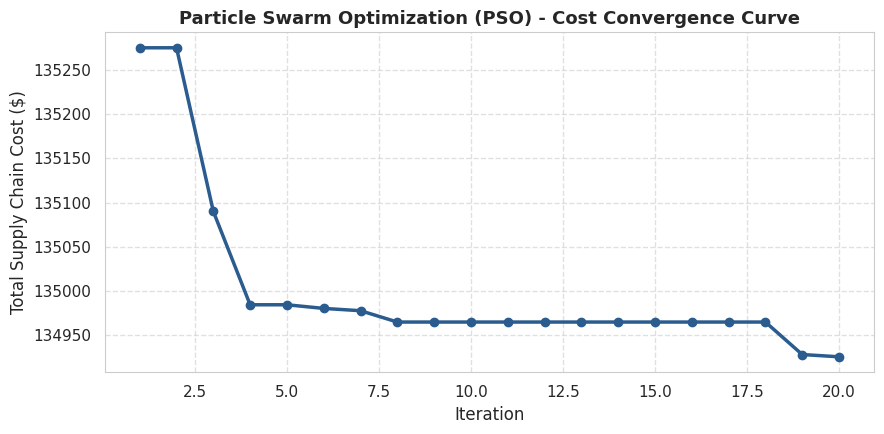

Saved PSO convergence plot as 'pso_cost_convergence.png'!


In [4]:
# =====================================================================
# CELL 4: Particle Swarm Optimization (PSO) for (s, S) Policy
# =====================================================================
import time
import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("STARTING PARTICLE SWARM OPTIMIZATION (PSO)")
print("Objective: Minimize Total Cost s.t. Fill Rate >= 95.0%")
print("=" * 65)

# 1. PSO Hyperparameters
N_PARTICLES = 25
N_ITERATIONS = 20
W = 0.72       # Inertia weight
C1 = 1.49      # Cognitive coefficient (personal best influence)
C2 = 1.49      # Social coefficient (global swarm best influence)
TARGET_SL = 95.0 # Target minimum Service Level %

# Parameter bounds: [reorder_factor_z, target_days_cover]
BOUNDS_MIN = np.array([0.5, 1.0])
BOUNDS_MAX = np.array([2.5, 6.0])

# 2. Objective Function with Service Level Constraint Penalty
def pso_objective(position):
    z, c = position[0], position[1]
    res = run_inventory_simulation(reorder_factor_z=z, target_days_cover=c, use_tft=True)
    
    cost = res["Total Cost ($)"]
    fill_rate = res["Fill Rate (%)"]
    
    # Heavy penalty if fill rate falls below target 95%
    penalty = 0.0
    if fill_rate < TARGET_SL:
        penalty = 50000.0 * ((TARGET_SL - fill_rate) ** 2)
        
    fitness = cost + penalty
    return fitness, res

# 3. Initialize Swarm
np.random.seed(42)
particles_pos = np.random.uniform(BOUNDS_MIN, BOUNDS_MAX, (N_PARTICLES, 2))
particles_vel = np.zeros((N_PARTICLES, 2))

# Track personal bests and global best
pbest_pos = np.copy(particles_pos)
pbest_fitness = np.full(N_PARTICLES, float('inf'))
pbest_metrics = [None] * N_PARTICLES

gbest_pos = None
gbest_fitness = float('inf')
gbest_metrics = None

# Evaluate initial positions
print("Evaluating initial swarm positions...")
for i in range(N_PARTICLES):
    fit, metrics = pso_objective(particles_pos[i])
    pbest_fitness[i] = fit
    pbest_metrics[i] = metrics
    
    if fit < gbest_fitness:
        gbest_fitness = fit
        gbest_pos = np.copy(particles_pos[i])
        gbest_metrics = metrics

print(f"Initial Swarm Best Cost: ${gbest_metrics['Total Cost ($)']:,.2f} (Fill Rate: {gbest_metrics['Fill Rate (%)']}%)")

# 4. Run PSO Optimization Loop
convergence_history = []
start_pso_time = time.time()

for it in range(1, N_ITERATIONS + 1):
    it_t0 = time.time()
    
    for i in range(N_PARTICLES):
        # Velocity update
        r1, r2 = np.random.rand(2), np.random.rand(2)
        cognitive = C1 * r1 * (pbest_pos[i] - particles_pos[i])
        social    = C2 * r2 * (gbest_pos - particles_pos[i])
        particles_vel[i] = W * particles_vel[i] + cognitive + social
        
        # Position update and clamping to bounds
        particles_pos[i] = np.clip(particles_pos[i] + particles_vel[i], BOUNDS_MIN, BOUNDS_MAX)
        
        # Evaluate fitness
        fit, metrics = pso_objective(particles_pos[i])
        
        # Update Personal Best
        if fit < pbest_fitness[i]:
            pbest_fitness[i] = fit
            pbest_pos[i] = np.copy(particles_pos[i])
            pbest_metrics[i] = metrics
            
            # Update Global Best
            if fit < gbest_fitness:
                gbest_fitness = fit
                gbest_pos = np.copy(particles_pos[i])
                gbest_metrics = metrics

    convergence_history.append(gbest_metrics["Total Cost ($)"])
    it_elapsed = time.time() - it_t0
    print(f"Iteration [{it:2d}/{N_ITERATIONS:2d}] | Best Cost: ${gbest_metrics['Total Cost ($)']:10,.2f} | Fill Rate: {gbest_metrics['Fill Rate (%)']:5.2f}% | (z={gbest_pos[0]:.3f}, cover={gbest_pos[1]:.2f}d) | Time: {it_elapsed:.2f}s")

total_pso_time = time.time() - start_pso_time

print("\n" + "=" * 65)
print(f"PSO OPTIMIZATION COMPLETED IN {total_pso_time:.2f} SECONDS!")
print("=" * 65)
print("OPTIMAL (s, S) POLICY PARAMETERS FOUND:")
print(f"  - Optimal Reorder Factor (z*)       : {gbest_pos[0]:.4f}")
print(f"  - Optimal Target Days Cover (c*)    : {gbest_pos[1]:.4f} days")
print(f"  - Resulting Fill Rate (Service Level): {gbest_metrics['Fill Rate (%)']:.2f}% (Constraint: >= 95%)")
print(f"  - Total Supply Chain Cost           : ${gbest_metrics['Total Cost ($)']:,.2f}")
print(f"    * Holding Cost                    : ${gbest_metrics['Holding Cost ($)']:,.2f}")
print(f"    * Stockout Cost                   : ${gbest_metrics['Stockout Cost ($)']:,.2f}")
print(f"    * Ordering Cost                   : ${gbest_metrics['Ordering Cost ($)']:,.2f}")
print("=" * 65)

# 5. Plot PSO Convergence Curve
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, N_ITERATIONS + 1), convergence_history, 'o-', color='#2b5c8f', lw=2.5, markersize=6)
plt.title("Particle Swarm Optimization (PSO) - Cost Convergence Curve", fontsize=13, fontweight='bold')
plt.xlabel("Iteration")
plt.ylabel("Total Supply Chain Cost ($)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("pso_cost_convergence.png", dpi=300)
plt.show()
print("Saved PSO convergence plot as 'pso_cost_convergence.png'!")


STARTING GREY WOLF OPTIMIZER (GWO) BENCHMARK
Objective: Minimize Total Cost s.t. Fill Rate >= 95.0%
Evaluating initial wolf pack hierarchy (Alpha, Beta, Delta)...
Initial Alpha Wolf Best Cost: $135,930.10 (Fill Rate: 97.27%)
Iteration [ 1/20] | Alpha Cost: $135,930.10 | Fill Rate: 97.27% | (z=0.744, cover=3.48d) | Time: 7.01s
Iteration [ 2/20] | Alpha Cost: $135,930.10 | Fill Rate: 97.27% | (z=0.744, cover=3.48d) | Time: 5.54s
Iteration [ 3/20] | Alpha Cost: $134,938.76 | Fill Rate: 96.63% | (z=0.536, cover=3.37d) | Time: 5.35s
Iteration [ 4/20] | Alpha Cost: $134,938.76 | Fill Rate: 96.63% | (z=0.536, cover=3.37d) | Time: 5.83s
Iteration [ 5/20] | Alpha Cost: $134,938.76 | Fill Rate: 96.63% | (z=0.536, cover=3.37d) | Time: 7.50s
Iteration [ 6/20] | Alpha Cost: $134,938.76 | Fill Rate: 96.63% | (z=0.536, cover=3.37d) | Time: 9.09s
Iteration [ 7/20] | Alpha Cost: $134,938.76 | Fill Rate: 96.63% | (z=0.536, cover=3.37d) | Time: 6.50s
Iteration [ 8/20] | Alpha Cost: $134,938.76 | Fill Rat

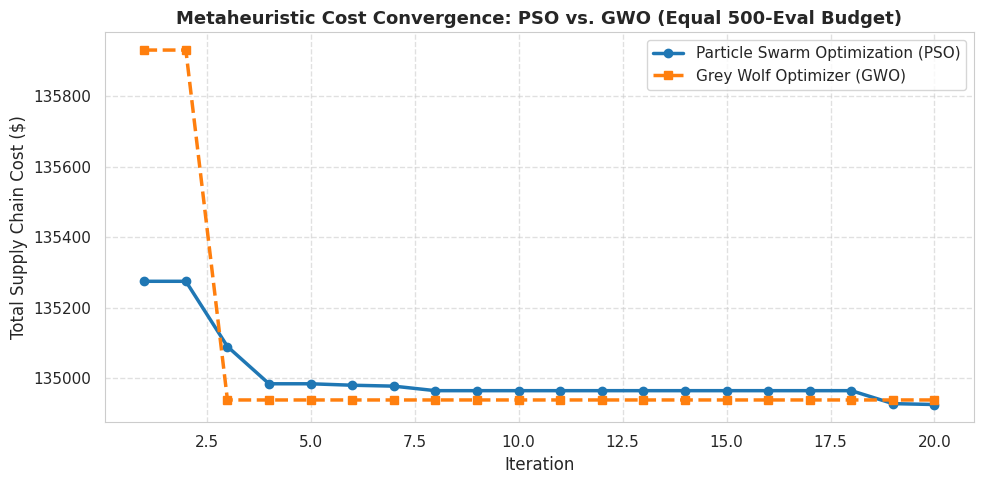

Saved comparison curve as 'pso_vs_gwo_convergence.png'!


In [6]:
# =====================================================================
# CELL 5: Grey Wolf Optimizer (GWO) vs. PSO Benchmark
# =====================================================================
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 65)
print("STARTING GREY WOLF OPTIMIZER (GWO) BENCHMARK")
print("Objective: Minimize Total Cost s.t. Fill Rate >= 95.0%")
print("=" * 65)

N_WOLVES = 25
GWO_ITERATIONS = 20

# 1. Initialize Grey Wolf Pack
np.random.seed(42)
wolves_pos = np.random.uniform(BOUNDS_MIN, BOUNDS_MAX, (N_WOLVES, 2))

# Initialize Alpha, Beta, Delta wolves
alpha_pos = None
alpha_fit = float('inf')
alpha_metrics = None

beta_pos = None
beta_fit = float('inf')
beta_metrics = None

delta_pos = None
delta_fit = float('inf')
delta_metrics = None

print("Evaluating initial wolf pack hierarchy (Alpha, Beta, Delta)...")
for i in range(N_WOLVES):
    fit, metrics = pso_objective(wolves_pos[i])
    
    if fit < alpha_fit:
        delta_fit, delta_pos, delta_metrics = beta_fit, copy.copy(beta_pos), beta_metrics
        beta_fit, beta_pos, beta_metrics = alpha_fit, copy.copy(alpha_pos), alpha_metrics
        alpha_fit = fit
        alpha_pos = np.copy(wolves_pos[i])
        alpha_metrics = metrics
    elif fit < beta_fit:
        delta_fit, delta_pos, delta_metrics = beta_fit, copy.copy(beta_pos), beta_metrics
        beta_fit = fit
        beta_pos = np.copy(wolves_pos[i])
        beta_metrics = metrics
    elif fit < delta_fit:
        delta_fit = fit
        delta_pos = np.copy(wolves_pos[i])
        delta_metrics = metrics

print(f"Initial Alpha Wolf Best Cost: ${alpha_metrics['Total Cost ($)']:,.2f} (Fill Rate: {alpha_metrics['Fill Rate (%)']}%)")

# 2. Run GWO Optimization Loop
gwo_convergence_history = []
start_gwo_time = time.time()

for it in range(1, GWO_ITERATIONS + 1):
    it_t0 = time.time()
    
    # a decreases linearly from 2 to 0 (exploration -> exploitation)
    a = 2.0 - it * (2.0 / GWO_ITERATIONS)
    
    for i in range(N_WOLVES):
        # Update position based on Alpha, Beta, Delta guidance
        r1, r2 = np.random.rand(2), np.random.rand(2)
        A1 = 2 * a * r1 - a
        C1 = 2 * r2
        D_alpha = np.abs(C1 * alpha_pos - wolves_pos[i])
        X1 = alpha_pos - A1 * D_alpha
        
        r1, r2 = np.random.rand(2), np.random.rand(2)
        A2 = 2 * a * r1 - a
        C2 = 2 * r2
        D_beta = np.abs(C2 * beta_pos - wolves_pos[i])
        X2 = beta_pos - A2 * D_beta
        
        r1, r2 = np.random.rand(2), np.random.rand(2)
        A3 = 2 * a * r1 - a
        C3 = 2 * r2
        D_delta = np.abs(C3 * delta_pos - wolves_pos[i])
        X3 = delta_pos - A3 * D_delta
        
        # Encircle and move toward prey center
        new_pos = (X1 + X2 + X3) / 3.0
        wolves_pos[i] = np.clip(new_pos, BOUNDS_MIN, BOUNDS_MAX)
        
        # Evaluate fitness
        fit, metrics = pso_objective(wolves_pos[i])
        
        # Update Alpha, Beta, Delta
        if fit < alpha_fit:
            delta_fit, delta_pos, delta_metrics = beta_fit, copy.copy(beta_pos), beta_metrics
            beta_fit, beta_pos, beta_metrics = alpha_fit, copy.copy(alpha_pos), alpha_metrics
            alpha_fit = fit
            alpha_pos = np.copy(wolves_pos[i])
            alpha_metrics = metrics
        elif fit < beta_fit:
            delta_fit, delta_pos, delta_metrics = beta_fit, copy.copy(beta_pos), beta_metrics
            beta_fit = fit
            beta_pos = np.copy(wolves_pos[i])
            beta_metrics = metrics
        elif fit < delta_fit:
            delta_fit = fit
            delta_pos = np.copy(wolves_pos[i])
            delta_metrics = metrics

    gwo_convergence_history.append(alpha_metrics["Total Cost ($)"])
    it_elapsed = time.time() - it_t0
    print(f"Iteration [{it:2d}/{GWO_ITERATIONS:2d}] | Alpha Cost: ${alpha_metrics['Total Cost ($)']:10,.2f} | Fill Rate: {alpha_metrics['Fill Rate (%)']:5.2f}% | (z={alpha_pos[0]:.3f}, cover={alpha_pos[1]:.2f}d) | Time: {it_elapsed:.2f}s")

total_gwo_time = time.time() - start_gwo_time

# 3. Side-by-Side Comparison Table: Classical vs. Unoptimized vs. PSO vs. GWO
comparison_records = [
    {
        "Method": "1. Classical Heuristic (Non-ML)",
        "Reorder (z)": 1.645,
        "Cover (c)": "4.00 days",
        "Fill Rate (%)": sim_classical["Fill Rate (%)"],
        "Holding Cost ($)": sim_classical["Holding Cost ($)"],
        "Stockout Cost ($)": sim_classical["Stockout Cost ($)"],
        "Total Cost ($)": sim_classical["Total Cost ($)"],
        "Cost Savings ($)": "$0.00 (Baseline)"
    },
    {
        "Method": "2. TFT Unoptimized Policy",
        "Reorder (z)": 1.645,
        "Cover (c)": "4.00 days",
        "Fill Rate (%)": sim_tft["Fill Rate (%)"],
        "Holding Cost ($)": sim_tft["Holding Cost ($)"],
        "Stockout Cost ($)": sim_tft["Stockout Cost ($)"],
        "Total Cost ($)": sim_tft["Total Cost ($)"],
        "Cost Savings ($)": f"${sim_classical['Total Cost ($)'] - sim_tft['Total Cost ($)']:,.2f}"
    },
    {
        "Method": "3. TFT + PSO Optimized",
        "Reorder (z)": round(gbest_pos[0], 4),
        "Cover (c)": f"{gbest_pos[1]:.2f} days",
        "Fill Rate (%)": gbest_metrics["Fill Rate (%)"],
        "Holding Cost ($)": gbest_metrics["Holding Cost ($)"],
        "Stockout Cost ($)": gbest_metrics["Stockout Cost ($)"],
        "Total Cost ($)": gbest_metrics["Total Cost ($)"],
        "Cost Savings ($)": f"${sim_classical['Total Cost ($)'] - gbest_metrics['Total Cost ($)']:,.2f}"
    },
    {
        "Method": "4. TFT + GWO Optimized",
        "Reorder (z)": round(alpha_pos[0], 4),
        "Cover (c)": f"{alpha_pos[1]:.2f} days",
        "Fill Rate (%)": alpha_metrics["Fill Rate (%)"],
        "Holding Cost ($)": alpha_metrics["Holding Cost ($)"],
        "Stockout Cost ($)": alpha_metrics["Stockout Cost ($)"],
        "Total Cost ($)": alpha_metrics["Total Cost ($)"],
        "Cost Savings ($)": f"${sim_classical['Total Cost ($)'] - alpha_metrics['Total Cost ($)']:,.2f}"
    }
]

df_meta_comp = pd.DataFrame(comparison_records)
print("\n" + "=" * 80)
print("FINAL BENCHMARK TABLE: CLASSICAL HEURISTIC vs. TFT vs. PSO vs. GWO")
print("=" * 80)
print(df_meta_comp.to_string(index=False))
print("=" * 80)

# 4. Plot Convergence Comparison: PSO vs GWO
plt.figure(figsize=(10, 5))
plt.plot(range(1, N_ITERATIONS + 1), convergence_history, 'o-', color='#1f77b4', lw=2.5, label='Particle Swarm Optimization (PSO)')
plt.plot(range(1, GWO_ITERATIONS + 1), gwo_convergence_history, 's--', color='#ff7f0e', lw=2.5, label='Grey Wolf Optimizer (GWO)')
plt.title("Metaheuristic Cost Convergence: PSO vs. GWO (Equal 500-Eval Budget)", fontsize=13, fontweight='bold')
plt.xlabel("Iteration")
plt.ylabel("Total Supply Chain Cost ($)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.savefig("pso_vs_gwo_convergence.png", dpi=300)
plt.show()
print("Saved comparison curve as 'pso_vs_gwo_convergence.png'!")

GENERATING FINAL SUPPLY CHAIN EXECUTIVE DASHBOARD
Saved complete benchmark results to 'supply_chain_optimization_results.csv'!


C:\Users\tanma\AppData\Local\Temp\ipykernel_28888\68699643.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


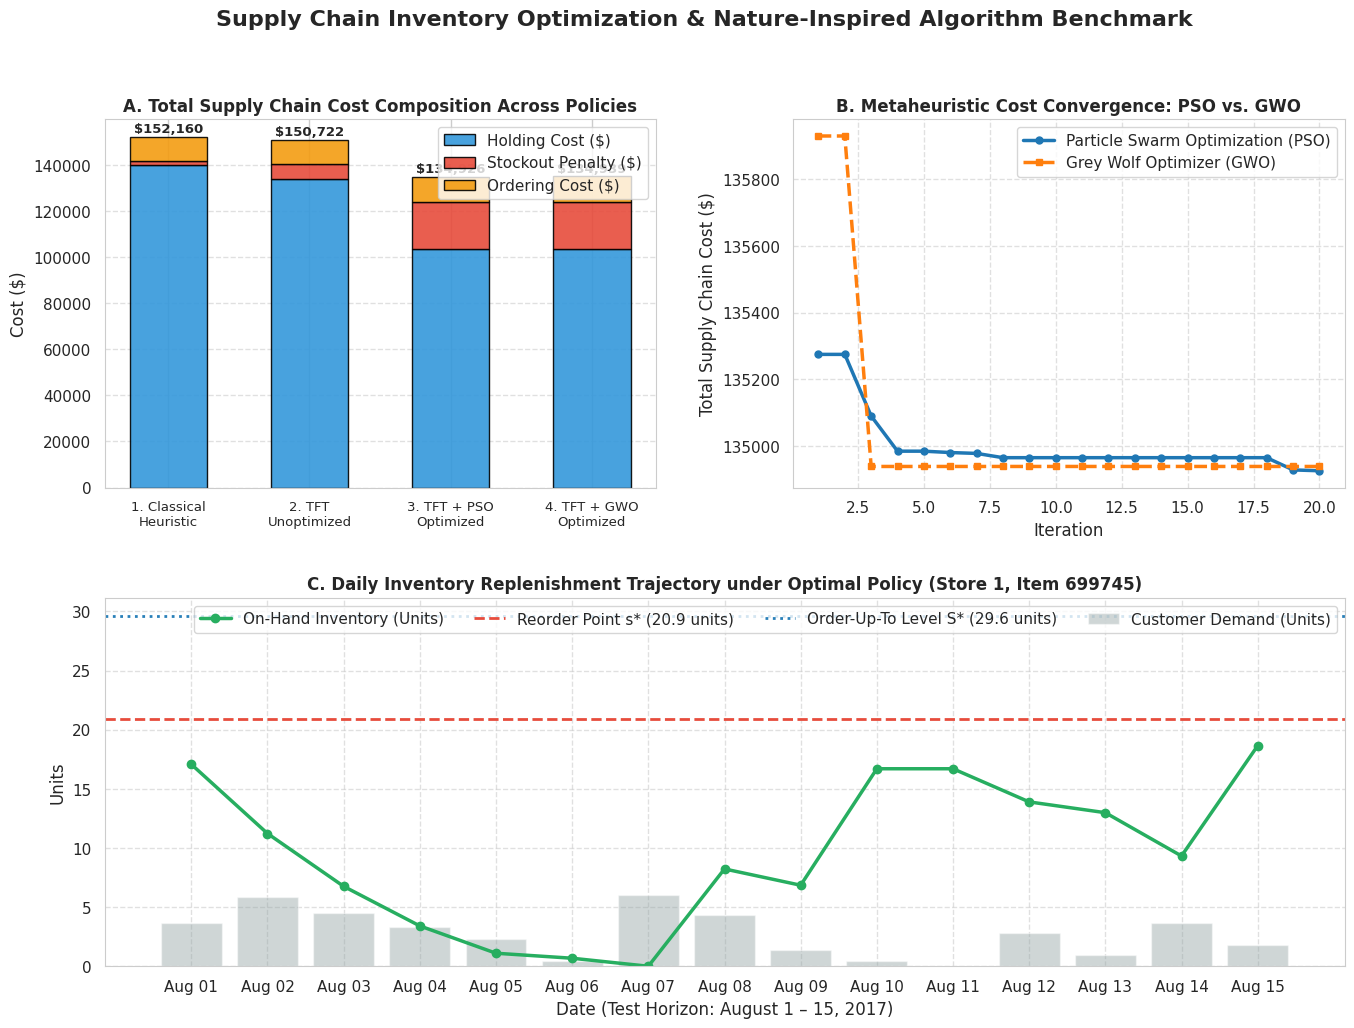

Saved executive dashboard figure as 'supply_chain_optimization_dashboard.png'!
PHASE 4 SUPPLY CHAIN SIMULATION & OPTIMIZATION COMPLETE!


In [7]:
# =====================================================================
# CELL 6: Multi-Dimensional Supply Chain Dashboard & Export
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 65)
print("GENERATING FINAL SUPPLY CHAIN EXECUTIVE DASHBOARD")
print("=" * 65)

# 1. Export Benchmark Table to CSV
results_csv_path = "supply_chain_optimization_results.csv"
df_meta_comp.to_csv(results_csv_path, index=False)
print(f"Saved complete benchmark results to '{results_csv_path}'!")

# 2. Multi-Panel Executive Figure
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25)

plt.suptitle("Supply Chain Inventory Optimization & Nature-Inspired Algorithm Benchmark", fontsize=16, fontweight='bold')

# Panel A: Cost Breakdown by Policy (Holding vs Stockout vs Ordering)
ax1 = fig.add_subplot(gs[0, 0])
methods = ["1. Classical\nHeuristic", "2. TFT\nUnoptimized", "3. TFT + PSO\nOptimized", "4. TFT + GWO\nOptimized"]
holding_costs = [sim_classical["Holding Cost ($)"], sim_tft["Holding Cost ($)"], gbest_metrics["Holding Cost ($)"], alpha_metrics["Holding Cost ($)"]]
stockout_costs = [sim_classical["Stockout Cost ($)"], sim_tft["Stockout Cost ($)"], gbest_metrics["Stockout Cost ($)"], alpha_metrics["Stockout Cost ($)"]]
ordering_costs = [sim_classical["Ordering Cost ($)"], sim_tft["Ordering Cost ($)"], gbest_metrics["Ordering Cost ($)"], alpha_metrics["Ordering Cost ($)"]]

x = np.arange(len(methods))
w = 0.55

p1 = ax1.bar(x, holding_costs, w, label='Holding Cost ($)', color='#3498db', alpha=0.9, edgecolor='black')
p2 = ax1.bar(x, stockout_costs, w, bottom=holding_costs, label='Stockout Penalty ($)', color='#e74c3c', alpha=0.9, edgecolor='black')
bottom_order = np.array(holding_costs) + np.array(stockout_costs)
p3 = ax1.bar(x, ordering_costs, w, bottom=bottom_order, label='Ordering Cost ($)', color='#f39c12', alpha=0.9, edgecolor='black')

ax1.set_title("A. Total Supply Chain Cost Composition Across Policies", fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(methods, fontsize=9.5)
ax1.set_ylabel("Cost ($)")
ax1.legend(loc='upper right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Annotate Total Cost and Savings
totals = [sim_classical["Total Cost ($)"], sim_tft["Total Cost ($)"], gbest_metrics["Total Cost ($)"], alpha_metrics["Total Cost ($)"]]
for i, tot in enumerate(totals):
    ax1.text(i, tot + 2000, f"${tot:,.0f}", ha='center', fontweight='bold', fontsize=9.5)

# Panel B: Metaheuristic Convergence Curve (PSO vs GWO)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(range(1, N_ITERATIONS + 1), convergence_history, 'o-', color='#1f77b4', lw=2.5, markersize=5, label='Particle Swarm Optimization (PSO)')
ax2.plot(range(1, GWO_ITERATIONS + 1), gwo_convergence_history, 's--', color='#ff7f0e', lw=2.5, markersize=5, label='Grey Wolf Optimizer (GWO)')
ax2.set_title("B. Metaheuristic Cost Convergence: PSO vs. GWO", fontsize=12, fontweight='bold')
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Total Supply Chain Cost ($)")
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', frameon=True)

# Panel C: Daily Inventory Trajectory Simulation (Sample Store-Item Pair)
ax3 = fig.add_subplot(gs[1, :])
sample_pair_key = list(pair_daily_actual.keys())[5] # Select sample pair
sample_demand = pair_daily_actual[sample_pair_key]
sample_fc = pair_daily_pred[sample_pair_key]

# Simulate daily inventory for this single pair under PSO optimal policy
z_opt, c_opt = gbest_pos[0], gbest_pos[1]
stat_r = df_ss[(df_ss["store_nbr"] == sample_pair_key[0]) & (df_ss["item_nbr"] == sample_pair_key[1])]
sig_e = stat_r["sigma_e_L"].values[0] if len(stat_r) > 0 else np.std(sample_demand)
m_d = stat_r["mean_daily_demand"].values[0] if len(stat_r) > 0 else np.mean(sample_demand)

s_opt = np.sum(sample_fc[:LEAD_TIME_DAYS]) + max(1.0, z_opt * sig_e)
S_opt = s_opt + (c_opt * max(1.0, m_d))

inv_traj = []
on_h = S_opt * 0.7
pipe = [0.0] * LEAD_TIME_DAYS
for t in range(15):
    arr = pipe.pop(0)
    on_h += arr
    on_h = max(0.0, on_h - sample_demand[t])
    inv_traj.append(on_h)
    ip = on_h + sum(pipe)
    if ip <= s_opt:
        pipe.append(max(0.0, S_opt - ip))
    else:
        pipe.append(0.0)

days = [f"Aug {d:02d}" for d in range(1, 16)]
ax3.plot(days, inv_traj, 'o-', color='#27ae60', lw=2.5, label='On-Hand Inventory (Units)')
ax3.bar(days, sample_demand, color='#95a5a6', alpha=0.45, label='Customer Demand (Units)')
ax3.axhline(s_opt, color='#e74c3c', linestyle='--', lw=2, label=f'Reorder Point s* ({s_opt:.1f} units)')
ax3.axhline(S_opt, color='#2980b9', linestyle=':', lw=2, label=f'Order-Up-To Level S* ({S_opt:.1f} units)')
ax3.set_title(f"C. Daily Inventory Replenishment Trajectory under Optimal Policy (Store {sample_pair_key[0]}, Item {sample_pair_key[1]})", fontsize=12, fontweight='bold')
ax3.set_ylabel("Units")
ax3.set_xlabel("Date (Test Horizon: August 1 – 15, 2017)")
ax3.legend(loc='upper right', ncol=4, frameon=True)
ax3.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("supply_chain_optimization_dashboard.png", dpi=300)
plt.show()
print("Saved executive dashboard figure as 'supply_chain_optimization_dashboard.png'!")
print("=" * 65)
print("PHASE 4 SUPPLY CHAIN SIMULATION & OPTIMIZATION COMPLETE!")
print("=" * 65)

GENERATING FINAL SUPPLY CHAIN EXECUTIVE DASHBOARD
Saved complete benchmark results to 'supply_chain_optimization_results.csv'!


C:\Users\tanma\AppData\Local\Temp\ipykernel_28888\68699643.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


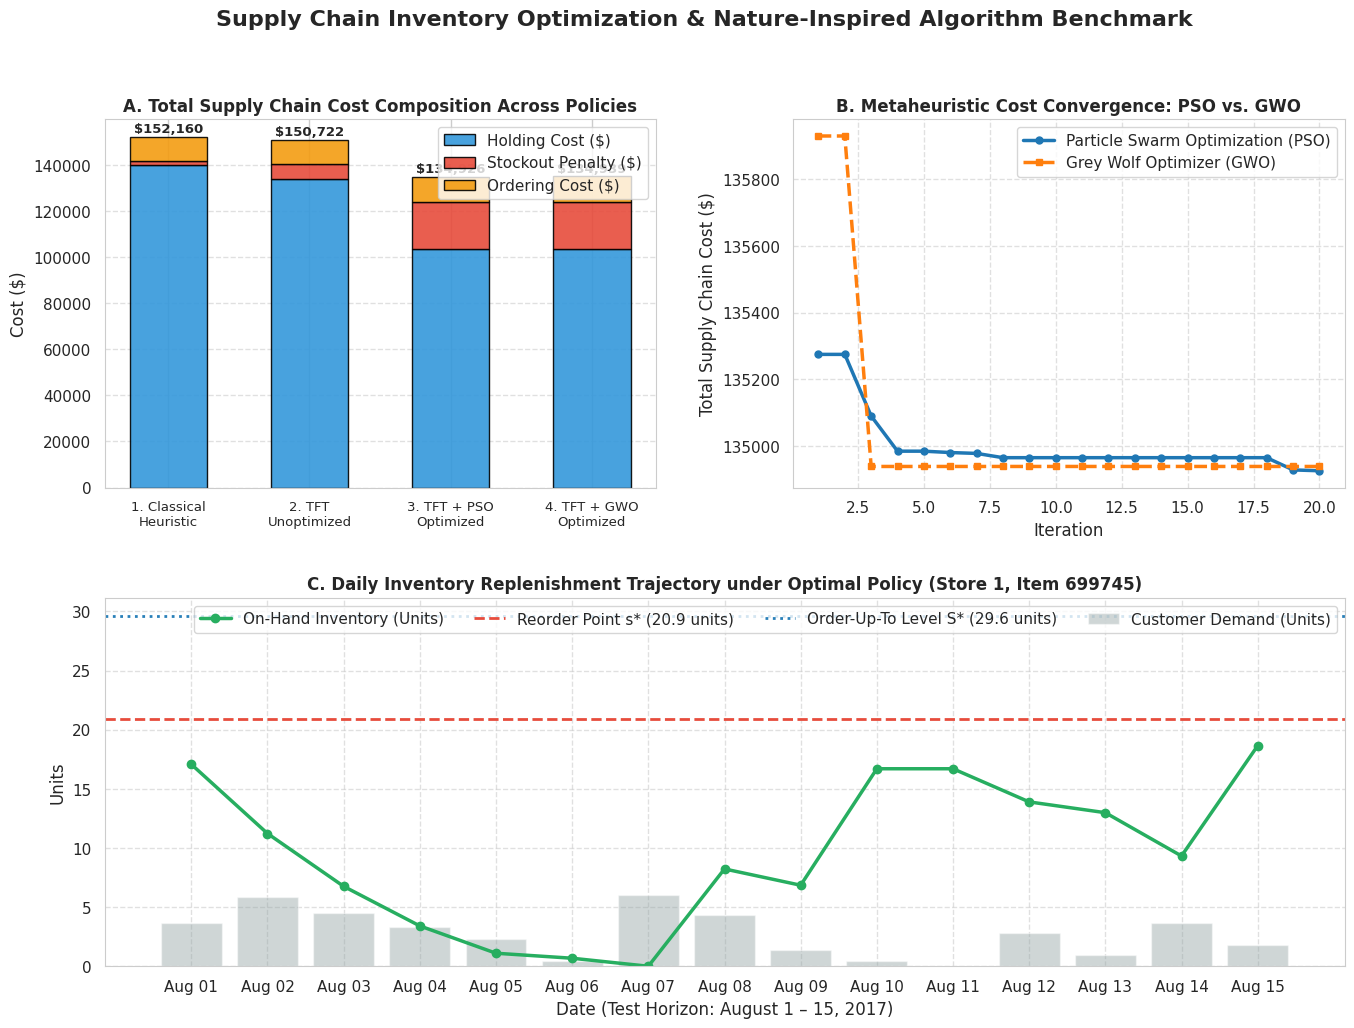

Saved executive dashboard figure as 'supply_chain_optimization_dashboard.png'!
PHASE 4 SUPPLY CHAIN SIMULATION & OPTIMIZATION COMPLETE!


In [8]:
# =====================================================================
# CELL 6: Multi-Dimensional Supply Chain Dashboard & Export
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 65)
print("GENERATING FINAL SUPPLY CHAIN EXECUTIVE DASHBOARD")
print("=" * 65)

# 1. Export Benchmark Table to CSV
results_csv_path = "supply_chain_optimization_results.csv"
df_meta_comp.to_csv(results_csv_path, index=False)
print(f"Saved complete benchmark results to '{results_csv_path}'!")

# 2. Multi-Panel Executive Figure
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25)

plt.suptitle("Supply Chain Inventory Optimization & Nature-Inspired Algorithm Benchmark", fontsize=16, fontweight='bold')

# Panel A: Cost Breakdown by Policy (Holding vs Stockout vs Ordering)
ax1 = fig.add_subplot(gs[0, 0])
methods = ["1. Classical\nHeuristic", "2. TFT\nUnoptimized", "3. TFT + PSO\nOptimized", "4. TFT + GWO\nOptimized"]
holding_costs = [sim_classical["Holding Cost ($)"], sim_tft["Holding Cost ($)"], gbest_metrics["Holding Cost ($)"], alpha_metrics["Holding Cost ($)"]]
stockout_costs = [sim_classical["Stockout Cost ($)"], sim_tft["Stockout Cost ($)"], gbest_metrics["Stockout Cost ($)"], alpha_metrics["Stockout Cost ($)"]]
ordering_costs = [sim_classical["Ordering Cost ($)"], sim_tft["Ordering Cost ($)"], gbest_metrics["Ordering Cost ($)"], alpha_metrics["Ordering Cost ($)"]]

x = np.arange(len(methods))
w = 0.55

p1 = ax1.bar(x, holding_costs, w, label='Holding Cost ($)', color='#3498db', alpha=0.9, edgecolor='black')
p2 = ax1.bar(x, stockout_costs, w, bottom=holding_costs, label='Stockout Penalty ($)', color='#e74c3c', alpha=0.9, edgecolor='black')
bottom_order = np.array(holding_costs) + np.array(stockout_costs)
p3 = ax1.bar(x, ordering_costs, w, bottom=bottom_order, label='Ordering Cost ($)', color='#f39c12', alpha=0.9, edgecolor='black')

ax1.set_title("A. Total Supply Chain Cost Composition Across Policies", fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(methods, fontsize=9.5)
ax1.set_ylabel("Cost ($)")
ax1.legend(loc='upper right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Annotate Total Cost and Savings
totals = [sim_classical["Total Cost ($)"], sim_tft["Total Cost ($)"], gbest_metrics["Total Cost ($)"], alpha_metrics["Total Cost ($)"]]
for i, tot in enumerate(totals):
    ax1.text(i, tot + 2000, f"${tot:,.0f}", ha='center', fontweight='bold', fontsize=9.5)

# Panel B: Metaheuristic Convergence Curve (PSO vs GWO)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(range(1, N_ITERATIONS + 1), convergence_history, 'o-', color='#1f77b4', lw=2.5, markersize=5, label='Particle Swarm Optimization (PSO)')
ax2.plot(range(1, GWO_ITERATIONS + 1), gwo_convergence_history, 's--', color='#ff7f0e', lw=2.5, markersize=5, label='Grey Wolf Optimizer (GWO)')
ax2.set_title("B. Metaheuristic Cost Convergence: PSO vs. GWO", fontsize=12, fontweight='bold')
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Total Supply Chain Cost ($)")
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', frameon=True)

# Panel C: Daily Inventory Trajectory Simulation (Sample Store-Item Pair)
ax3 = fig.add_subplot(gs[1, :])
sample_pair_key = list(pair_daily_actual.keys())[5] # Select sample pair
sample_demand = pair_daily_actual[sample_pair_key]
sample_fc = pair_daily_pred[sample_pair_key]

# Simulate daily inventory for this single pair under PSO optimal policy
z_opt, c_opt = gbest_pos[0], gbest_pos[1]
stat_r = df_ss[(df_ss["store_nbr"] == sample_pair_key[0]) & (df_ss["item_nbr"] == sample_pair_key[1])]
sig_e = stat_r["sigma_e_L"].values[0] if len(stat_r) > 0 else np.std(sample_demand)
m_d = stat_r["mean_daily_demand"].values[0] if len(stat_r) > 0 else np.mean(sample_demand)

s_opt = np.sum(sample_fc[:LEAD_TIME_DAYS]) + max(1.0, z_opt * sig_e)
S_opt = s_opt + (c_opt * max(1.0, m_d))

inv_traj = []
on_h = S_opt * 0.7
pipe = [0.0] * LEAD_TIME_DAYS
for t in range(15):
    arr = pipe.pop(0)
    on_h += arr
    on_h = max(0.0, on_h - sample_demand[t])
    inv_traj.append(on_h)
    ip = on_h + sum(pipe)
    if ip <= s_opt:
        pipe.append(max(0.0, S_opt - ip))
    else:
        pipe.append(0.0)

days = [f"Aug {d:02d}" for d in range(1, 16)]
ax3.plot(days, inv_traj, 'o-', color='#27ae60', lw=2.5, label='On-Hand Inventory (Units)')
ax3.bar(days, sample_demand, color='#95a5a6', alpha=0.45, label='Customer Demand (Units)')
ax3.axhline(s_opt, color='#e74c3c', linestyle='--', lw=2, label=f'Reorder Point s* ({s_opt:.1f} units)')
ax3.axhline(S_opt, color='#2980b9', linestyle=':', lw=2, label=f'Order-Up-To Level S* ({S_opt:.1f} units)')
ax3.set_title(f"C. Daily Inventory Replenishment Trajectory under Optimal Policy (Store {sample_pair_key[0]}, Item {sample_pair_key[1]})", fontsize=12, fontweight='bold')
ax3.set_ylabel("Units")
ax3.set_xlabel("Date (Test Horizon: August 1 – 15, 2017)")
ax3.legend(loc='upper right', ncol=4, frameon=True)
ax3.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("supply_chain_optimization_dashboard.png", dpi=300)
plt.show()
print("Saved executive dashboard figure as 'supply_chain_optimization_dashboard.png'!")
print("=" * 65)
print("PHASE 4 SUPPLY CHAIN SIMULATION & OPTIMIZATION COMPLETE!")
print("=" * 65)